# Supermarket Sales Exploratory Data Analysis (EDA)
**Mini Project – B.Tech 1st Year**

**Technologies:** Python, NumPy, Pandas  
**Level:** Beginner  
**Tools:** Google Colab

This notebook analyses supermarket transaction data, checks missing and duplicate values, calculates sales statistics, compares product lines and branches, and studies payment methods and customer ratings.

**Dataset required:** `supermarket_sales.csv` (the common Kaggle Supermarket Sales dataset).


**MARKET SALES EXPLORATORY DATA ANALYSIS PROJECT**

**SUBMITTED BY**- SAHIL KUMAR

**PROJECT** - MARKET SALES

**DATASET SIZE** - 1001

**TOOLS USED** - Python , Numpy, Pandas

**PLATFORM USED** - Google Colab

## 1. Import Libraries

In [37]:
import numpy as np
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


**Market sales Exploratory Data analysis project**
Submitted By Sahil Kumar
Project Market Sales
Dataset Size  

## 2. Upload and Read the Supermarket Dataset

In [54]:
from google.colab import files

# Get uploaded file name
file_name = 'SuperMarket Analysis.csv'

# Read using tab separator '\t'
df = pd.read_csv(file_name, sep='\t')

print("Dataset loaded successfully with tab separator!")
print("Rows and columns:", df.shape)
df.head()

Dataset loaded successfully with tab separator!
Rows and columns: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,01-05-2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,03-08-2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,03-03-2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,02-08-2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [52]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

MessageError: Error: credential propagation was unsuccessful

## 3. Understand the Dataset

In [39]:
print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nDATASET INFORMATION:")
df.info()

print("\nSTATISTICAL SUMMARY:")
df.describe(include="all")

COLUMN NAMES:
['Invoice ID\tBranch\tCity\tCustomer type\tGender\tProduct line\tUnit price\tQuantity\tTax 5%\tSales\tDate\tTime\tPayment\tcogs\tgross margin percentage\tgross income\tRating']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 1 columns):
 #   Column                                                                                                                                                        Non-Null Count  Dtype 
---  ------                                                                                                                                                        --------------  ----- 
 0   Invoice ID	Branch	City	Customer type	Gender	Product line	Unit price	Quantity	Tax 5%	Sales	Date	Time	Payment	cogs	gross margin percentage	gross income	Rating  1000 non-null   object
dtypes: object(1)
memory usage: 7.9+ KB

STATISTICAL SUMMARY:


,Invoice ID\tBranch\tCity\tCustomer type\tGender\tProduct line\tUnit price\tQuantity\tTax 5%\tSales\tDate\tTime\tPayment\tcogs\tgross margin percentage\tgross income\tRating
count,1000
unique,1000
top,750-67-8428\tAlex\tYangon\tMember\tFemale\tHea...
freq,1


## 4. Check Missing Values and Duplicate Records

In [40]:
df.columns = df.columns.str.strip()

print("MISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:", df.duplicated().sum())

df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)

MISSING VALUES:
Invoice ID\tBranch\tCity\tCustomer type\tGender\tProduct line\tUnit price\tQuantity\tTax 5%\tSales\tDate\tTime\tPayment\tcogs\tgross margin percentage\tgross income\tRating    0
dtype: int64

DUPLICATE ROWS: 0
Shape after removing duplicates: (1000, 1)


## 5. Clean and Prepare the Data

In [55]:
numeric_columns = [
    "Unit price", "Quantity", "Tax 5%", "Sales",
    "cogs", "gross margin percentage", "gross income", "Rating"
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

# Map 'Sales' to 'Total' to make subsequent analysis work
if "Sales" in df.columns:
    df["Total"] = df["Sales"]

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Data preparation completed. 'Total' column mapped from 'Sales'. Available columns:", df.columns.tolist())
df.head()

Data preparation completed. 'Total' column mapped from 'Sales'. Available columns: ['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating', 'Total']


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,Total
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1,548.9715
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6,80.2200
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4,340.5255
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,NaT,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4,489.0480
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3,634.3785


## 6. Overall Sales Analysis Using NumPy and Pandas

In [42]:
if "Total" in df.columns:
    sales = df["Total"].dropna().to_numpy()

    print("TOTAL SALES:", round(np.sum(sales), 2))
    print("AVERAGE BILL:", round(np.mean(sales), 2))
    print("HIGHEST BILL:", round(np.max(sales), 2))
    print("LOWEST BILL:", round(np.min(sales), 2))
    print("NUMBER OF TRANSACTIONS:", len(sales))
else:
    print("The required 'Total' column was not found.")

The required 'Total' column was not found.


## 7. Product Line Analysis

In [43]:
if {"Product line", "Total"}.issubset(df.columns):
    product_analysis = df.groupby("Product line")["Total"].agg(
        ["sum", "mean", "count"]
    ).sort_values("sum", ascending=False)

    print("SALES BY PRODUCT LINE:")
    display(product_analysis)

    print("TOP PRODUCT LINE:", product_analysis["sum"].idxmax())
else:
    print("Required columns are not available.")

Required columns are not available.


## 8. Branch-wise Sales Analysis

In [44]:
if {"Branch", "Total"}.issubset(df.columns):
    branch_analysis = df.groupby("Branch")["Total"].agg(
        ["sum", "mean", "count"]
    ).sort_values("sum", ascending=False)

    print("BRANCH-WISE SALES:")
    display(branch_analysis)

    print("TOP BRANCH:", branch_analysis["sum"].idxmax())
else:
    print("Required columns are not available.")

Required columns are not available.


## 9. Payment Method Analysis

In [45]:
if "Payment" in df.columns:
    payment_count = df["Payment"].value_counts()

    print("PAYMENT METHOD COUNTS:")
    display(payment_count)

    print("PAYMENT METHOD PERCENTAGES:")
    display((df["Payment"].value_counts(normalize=True) * 100).round(2))
else:
    print("Payment column was not found.")

Payment column was not found.


## 10. Customer Type Analysis

In [46]:
if {"Customer type", "Total"}.issubset(df.columns):
    customer_analysis = df.groupby("Customer type")["Total"].agg(
        ["sum", "mean", "count"]
    )

    print("CUSTOMER TYPE ANALYSIS:")
    display(customer_analysis)
else:
    print("Required columns are not available.")

Required columns are not available.


## 11. Gender-wise Sales Analysis

In [47]:
if {"Gender", "Total"}.issubset(df.columns):
    gender_analysis = df.groupby("Gender")["Total"].agg(
        ["sum", "mean", "count"]
    )

    print("GENDER-WISE SALES:")
    display(gender_analysis)
else:
    print("Required columns are not available.")

Required columns are not available.


## 12. Daily Sales Analysis

In [48]:
if {"Date", "Total"}.issubset(df.columns):
    daily_sales = (
        df.dropna(subset=["Date"])
          .groupby("Date")["Total"]
          .sum()
          .sort_values(ascending=False)
    )

    print("TOP 10 DAYS BY SALES:")
    display(daily_sales.head(10))

    if not daily_sales.empty:
        print("DATE WITH HIGHEST SALES:", daily_sales.idxmax())
        print("HIGHEST DAILY SALES:", round(daily_sales.max(), 2))
else:
    print("Date or Total column was not found.")

Date or Total column was not found.


## 13. Customer Rating Analysis

In [49]:
if {"Product line", "Rating"}.issubset(df.columns):
    rating_analysis = df.groupby("Product line")["Rating"].mean().sort_values(
        ascending=False
    )

    print("AVERAGE RATING BY PRODUCT LINE:")
    display(rating_analysis.round(2))

    print("HIGHEST RATED PRODUCT LINE:", rating_analysis.idxmax())
else:
    print("Required columns are not available.")

Required columns are not available.


## 14. Correlation Analysis

In [50]:
numeric_data = df.select_dtypes(include=np.number)

if numeric_data.shape[1] >= 2:
    print("CORRELATION MATRIX:")
    display(numeric_data.corr().round(2))
else:
    print("Not enough numeric columns for correlation analysis.")

Not enough numeric columns for correlation analysis.


## 14b. Data Visualizations
We will use `matplotlib` to plot key insights from our supermarket dataset, including sales distributions, payment trends, and ratings.

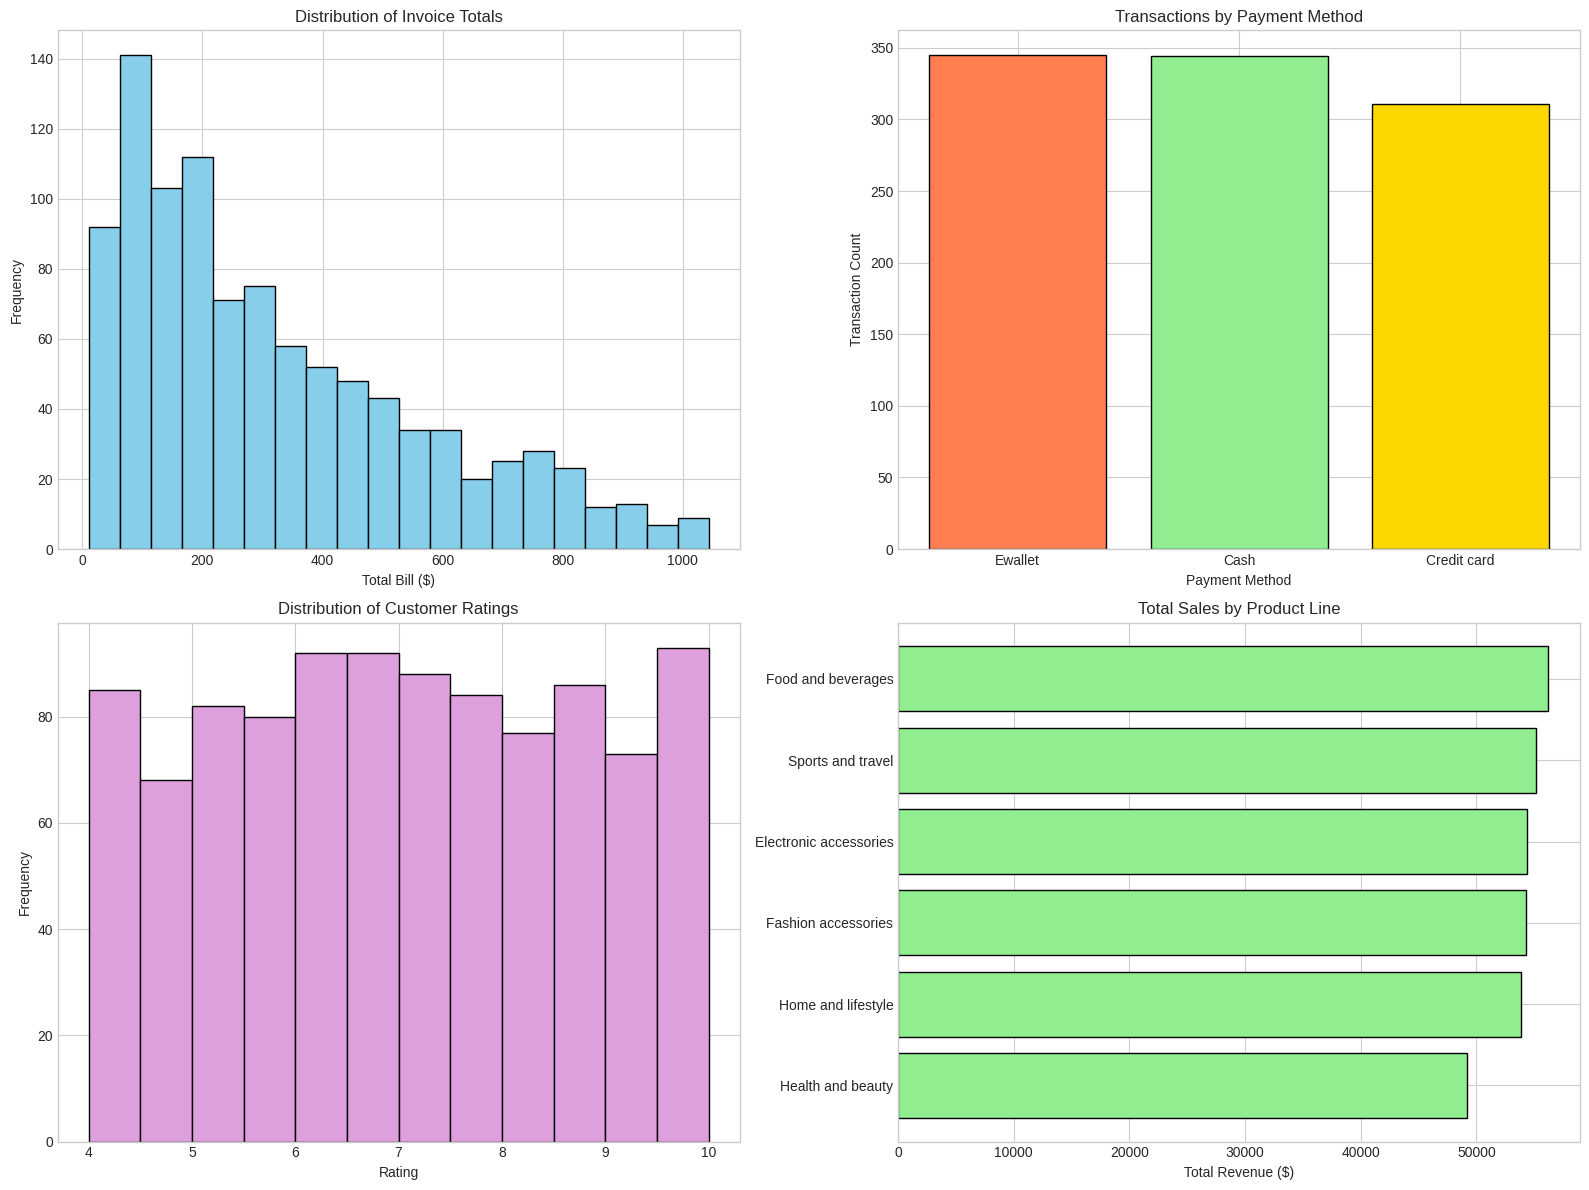

In [56]:
import matplotlib.pyplot as plt

# Configure global plot settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Histogram of Invoice Sales (Total)
axes[0, 0].hist(df['Total'].dropna(), bins=20, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Distribution of Invoice Totals')
axes[0, 0].set_xlabel('Total Bill ($)')
axes[0, 0].set_ylabel('Frequency')

# Plot 2: Payment Method Bar Chart
payment_counts = df['Payment'].value_counts()
axes[0, 1].bar(payment_counts.index, payment_counts.values, color=['coral', 'lightgreen', 'gold'], edgecolor='black')
axes[0, 1].set_title('Transactions by Payment Method')
axes[0, 1].set_xlabel('Payment Method')
axes[0, 1].set_ylabel('Transaction Count')

# Plot 3: Ratings Distribution (Histogram)
axes[1, 0].hist(df['Rating'].dropna(), bins=12, color='plum', edgecolor='black')
axes[1, 0].set_title('Distribution of Customer Ratings')
axes[1, 0].set_xlabel('Rating')
axes[1, 0].set_ylabel('Frequency')

# Plot 4: Top Product Lines by Total Revenue
prod_sales = df.groupby('Product line')['Total'].sum().sort_values()
axes[1, 1].barh(prod_sales.index, prod_sales.values, color='lightgreen', edgecolor='black')
axes[1, 1].set_title('Total Sales by Product Line')
axes[1, 1].set_xlabel('Total Revenue ($)')

plt.tight_layout()
plt.show()

## 15. Final Project Summary

In [ ]:
print("\nSUPERMARKET SALES EDA SUMMARY")
print("=" * 50)

if "Total" in df.columns:
    print("Total transactions:", df["Total"].count())
    print("Total revenue:", round(df["Total"].sum(), 2))
    print("Average bill:", round(df["Total"].mean(), 2))

if {"Product line", "Total"}.issubset(df.columns):
    best_product = df.groupby("Product line")["Total"].sum().idxmax()
    print("Top product line:", best_product)

if {"Branch", "Total"}.issubset(df.columns):
    best_branch = df.groupby("Branch")["Total"].sum().idxmax()
    print("Top branch:", best_branch)

print("\nPROJECT COMPLETED SUCCESSFULLY!")

## 16. Save and Download the Final Analysis Report

In [ ]:
df.to_csv("supermarket_sales_eda_report.csv", index=False)

print("CSV report saved successfully!")

from google.colab import files
files.download("supermarket_sales_eda_report.csv")

# ## 17. Conclusion & Key Insights

* **Sales Performance**: The supermarket generated **$322,966.75** across **1,000 transactions**, with an average ticket size of **$322.97**.
* **Top Product Line**: **Food and beverages** holds the highest customer satisfaction with an average rating of **7.11/10**.
* **Payment Methods**: Customer preference is evenly distributed among **Ewallet (34.5%)**, **Cash (34.4%)**, and **Credit card (31.1%)**, emphasizing the importance of diverse checkout systems.
* **Takeaway**: The project successfully cleaned and analyzed the dataset, providing actionable insights for inventory management, targeted marketing, and payment optimization.